# Chapter 7: Convolutional Neural Networks

* Want to leverage knowledge that nearby pixels typically relate to each other and exploit spatial structure better that way

# 7.1 From Fully Connected Layers to Convolutions

* If were were to use single fully connected layer for 1 megapixel (1000 by 1000 pixel)
    * $10^6 \times 10^3 = 10^9$ parameters (for grayscale, no RBG)
    * Large count for hypothetical case, underestimates amount of parameters needed to learn good representations/features 
    * A larger model would require more data to fit

### 7.1.1 Invariance
Not concerned with precise location of image - won't change the meaning of the image significantly if translated about the frame

Design Constraints:
1. Earliest Layers: Network should respond similarly to the same patch regardless of where ti is in image. Principle of _translation invariance_. (a.k.a. _translation equivarance_)
2. Earliest layers of network should focus on local regions and disregard contents of images in distant regions. Principle of _locality_. Eventually, local representations/features can be aggregated to make image-level predictions
3. Deeper layers should focus on longer-range features of the images

### 7.1.2 Constraining the MLP

* Consider an MLP with 2D images $X$ as inputs and immediate hidden representations $H$ that can be represented as matrices of the same shape. Consider the case if inputs & hidden representations possess spatial structure 
    * $[X]_{i, j}$: Pixel at location $(i, j)$ in the input image
    * $[H]_{i, j}$: Pixel at location $(i, j)$ in the hidden representation
* Instead of using matricies to represent weight as was in MLP, use 4-th order Weight tensors $W$. Call our biases $U$. 
    * MLP was 1 index to 1 index, so 2 orders (i.e. matrix) is appropriate 
    * Image has 2 indcies to 2 indices, so 4 orders (4th order tensor) 
* Connected layer can be expressed as the following: 
$$[H]_{i,j}=[U]_{i,j}+\sum_k \sum_i [W]_{i,j,k,l}[X]_{k,l}$$
$$[H]_{i,j}=[U]_{i,j}+\sum_a \sum_b [V]_{i,j,a,b}[X]_{i+a,j+b}$$
* Where switch from $W$ to $V$ is entirely cosmetic due to one-to-one correspondence between coefficients in both 4-th order tensors. Subscripts are re-indexed as follows:
    * $k=i+a$
    * $l=j+b$
* Indices $a$ and $b$ run over both positive & negative offsets, thus covering the entire image range
* For each $(i, j)$ of the hidden representation $[H]_{i,j}$, we compute its value by summing over pixels of $X$, $x$ centered about $(i, j)$ and weighted by $[V]_{i,j,a,b}$ 
* At this point, we note the parameter count needed for this kind of MLP input->hidden representation: $10^6$ in the input, and $10^6$ in the hidden, for a total parameter count of $10^12$ (1 trillion) for a single layer of this kind of MLP (quite a lot...)


#### Translational Invariance
* First, invoke principle of translational invariance that shift in input $X$ should not lead to shift in hidden representation $H$. This is only possible if we decouple $V$ and $U$ from $(i,j)$. 
    * $[V]_{i,j,a,b} \rightarrow [V]_{a,b}$
    * $[U] \rightarrow u$ ($u$ is constant)
$$ [H]_{i,j} = u + \sum_a \sum_b [V]_{a,b} [X]_{i+a, j+b}$$
* This is a _convolution_ where we effectively weigh pixels in vicininty $(i+a,j+b)$ of location in question $(i,j)$ with coefficients $[V]_{a,b}$ to obtain the value of $[H]_{i,j}$. 
    * Notice that $[V]_{a,b}$ needs fewer coefficients thatn $[V]_{i,j,a,b}$ since it no longer depends on the location of the pixel in quesion (no more $i,j$ dependence)
    * Need a more reasonable $4 \times 10^6$ parameters compared to the $10^12$ before. 
    * Parameters come from possible offsets of $-1000,1000$ per width/height, so $2000 \times 2000 = 4\times 10^6$

#### Locality
* Assumption that hidden representation at $(i,j)$ should influenced by pixels closest to it in the corresponding pixel of the input, and not by pixels far away. Mathematically, that would correspond to setting $[V]_{a,b} = 0$ for $|a|>\Delta$ or $|b|> \Delta$. 
$$ [H]_{i,j} = u + \sum_{a=-\Delta}^{\Delta} \sum_{b=-\Delta}^{\Delta} [V]_{a,b} [X]_{i+a,j+b}$$
* This reduces parameter count from $4 \times 10^6$ to $4\Delta^2$ where $\Delta$ is typically smaller than $10$. Notice we have reduced our parameter count by over 4 orders of magnitude
* In deep learning, $V$ is referred to as a _convolutional kernel_, a _filter_, or simply a layer's _weights_ that are learnable parameters 


* Trade off for drastic reduction in parameter count ithat our features are now translation invariant and layers/filters can only incorporate local information when determining value of each hidden acvtivation
* All learning depends on imposing inductive biases, and when said biases agree with reality, we get sample-efficient models that generalize well to unseen data. Note if our inductive biases don't reflect reality well (i.e. in our case, images are not dependent on local features nor translation invariant), then we may not even be able to fit our training data
* We can have deeper layers represent larger and more complex aspects of an image by weaving in nonlinearities and convolutional layers repeatedly

### 7.1.3 Convolutions

In math, a _convolution_ between two functions is defined as follows:
$$ (f \ast g)(x) = \int f(z)g(x-z) dz $$
Where we measure the overlap between functions $f$ and $g$ when one function is "flipped" and shifted by $x$. Whenever we have discrete objects, the integral turns into a summation. Take for example the vectors from set of square-summable infinite-dimensional vectors with index running over $\mathbb{Z}$ we get:
$$ (f \ast g)(i) = \sum_a f(a)g(i-a)$$
For 2-d tensors, we have a corresponding sum with indices $(a,b)$ for $f$ and $(i-a,j-b)$ for $g$ respectively: 
$$ (f \ast g)(i,j) = \sum_a \sum_b f(a,b) g(i-a,j-b)$$
Comparing with derivation of convolutional filters above, the difference in $-a$ or $+a$ is just difference in indexing notation and we can always match notations. NOTE - the convolutional filter derived earlier is more properly described as a _cross-correlation_. 

### 7.1.4 Channels

* There are RBG channels, not just a single color channel (which would just be grayscale). Below, the additional dimension refers to the channel dimension. We also want an entire vector (corresponding to each color channel) at each spatial location within the hidden layer (Where $d$ indexes output channels in hidden representations $H$). 
    * $[X]_{i,j} \rightarrow [X]_{i,j,c}$
    * $[V]_{a,b} \rightarrow [V]_{a,b,c}$
    * $[H]_{i,j} \rightarrow [H]_{i,j,d} \in \mathbb{R}^3$  
    * $[V]_{a,b,c} \rightarrow [V]_{a,b,c,d} $ 
$$ [H]_{i,j,d} = \sum_{a=-\Delta}^{\Delta} \sum_{b=-\Delta}^{\Delta} \sum_{c} [V]_{a,b,c,d} [X]_{i+a,j+b,c}$$

### 7.1.5 Summary and Discussion

* Derive CNN from first principles (locality & translational invariance)
* Add channels for RBG (rather than just grayscale)

### 7.1.6 Exercises
1. Assume that the size of the convolution kernel is $\Delta = 0$.
   Show that in this case the convolution kernel
   implements an MLP independently for each set of channels. This leads to the Network in Network 
   architectures Lin.Chen.Yan.2013. 
1. Audio data is often represented as a one-dimensional sequence. 
    1. When might you want to impose locality and translation invariance for audio? 
    1. Derive the convolution operations for audio.
    1. Can you treat audio using the same tools as computer vision? Hint: use the spectrogram.
1. Why might translation invariance not be a good idea after all? Give an example. 
1. Do you think that convolutional layers might also be applicable for text data?
   Which problems might you encounter with language?
1. What happens with convolutions when an object is at the boundary of an image?
1. Prove that the convolution is symmetric, i.e., $f * g = g * f$.

Exercise #1

$\Delta =0$, then: 
$$ [H]_{i,j,d} = \sum_{a=-\Delta}^{\Delta} \sum_{b=-\Delta}^{\Delta} \sum_{c} [V]_{a,b,c,d} [X]_{i+a,j+b,c}$$
becomes:
$$ [H]_{i,j,d} =  \sum_{c} [V]_{0,0,c,d} [X]_{i,j,c} = \sum_{c} [W]_{c,d} [X]_{i,j,c}$$
Which is just an MLP applied along each channel for each spatial location

Exercise #2

# Skip: I'll come back to this later

Exercise #3

There may be applications where translational invariance and/or locality do not apply. Text comes to mind, where shifting a filiter along text and thus changing the window of words in question would drastically change the meaning. Additionally, locality could be violated in text where a word or series of words "far away" from the sequence of text in question could have a meaningful effect on the meaning/interpretation of the current sequence. 

Exercise #4

Maybe, but possibly no, because translational invariance is a much stronger, less reasonable assumoption for text than it is with images. 

Exercise #5

Parts of the filter wouldn't have a corresponding input from that layer to "weigh" with its set of weights. Thus, either the hidden dimension must be smaller than the input layer, or some heuristics would have to be used to allow the center of the filter to reach points where the filter "overflows" from the input (say set extra boundary points with 0's or continue same pixels at "original" input)

Exercise #6

LHS:

$$
(f \ast g)(x) = \int_{-\infty}^{\infty} f(z)g(x-z) \, dz
$$

Take $u = x-z$, thus $du = -dz$ and the limits of integration change from $-\infty, \infty$ to $\infty, -\infty$.

$$
(f \ast g)(x) = \int_{\infty}^{-\infty} -f(x-u)g(u) \, du 
= \int_{-\infty}^{\infty} g(u)f(x-u) \, du
$$

Where we see that $u$ is a dummy variable, so this can be renamed to see that it has the same structure/functinality as:

RHS:

$$
(g \ast f)(x) = \int_{-\infty}^{\infty} g(z)f(x-z) 
$$

# 7.2 Convolutions for Images

### 7.2.1 The Cross-Correlation Operation

* Multiple all overlapping pairs within input & filter, then add to get corresponding hidden representaiton
* Size of Hidden Representation will be: $ (n_h - k_h + 1) \times (n_w - k_w + 1)$, where the input size is $n_h \times n_w$ and the convolution kernel is size $k_h \times k_w$ 
    * "Padding" will be covered layer

In [3]:
import torch
from torch import nn
from d2l import torch as d2l

def corr2d(X, K):
    """Calculate 2D cross-correlation between input X and kernel K."""
    h, w = K.shape
    Y = torch.zeros( (X.shape[0] - h + 1, X.shape[1] - w + 1) )
    for i in range(Y.shape[0]):     # height
        for j in range(Y.shape[1]): # width
            Y[i,j] = (X[i:i+h, j:j+w] * K).sum()
    return Y

# Test to see if it agrees with manual calculation in textbook
X = torch.tensor([[0.0, 1.0, 2.0], [3.0, 4.0, 5.0], [6.0, 7.0, 8.0]])
K = torch.tensor([[0.0, 1.0], [2.0, 3.0]])
corr2d(X, K)

tensor([[19., 25.],
        [37., 43.]])

### 7.2.2 Convolutional Layers

* Same thing as before, but so it can be used as a a layer within a neural network. Use the function declared earlier for convience. 
* In the init method, we declare the weight and bias of the convolutional layer. 
* Forward method implemented corr2d and adds in bias

In [4]:
class Conv2D(nn.Module):
    def __init__(self, kernel_size: tuple):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(kernel_size))
        self.bias   = nn.Parameter(torch.zeros(1))  
        # Need same bias for every spatial location (translational invariance ig)
        # I'm guessing broadcasting is applied when we add bias to output of corr2d

    def forward(self, X):
        return corr2d(X, self.weight) + self.bias

### 7.2.3 Object Edge Detection in Images

* Detecting an object in an image by finding location of pixel change 
* Construct image of $6\times 8$ pixels where middle 4 columns set to 0 and outer columns are set to 1
* We will construct a kernel with height 1 and width 2
    * We want it so when horizontal elements are the same, it returns a 0 but if horizontal elements are different, it returns a non-zero value
    * try (1, -1)
    * Note - this is a special case of finite difference operator (like a discrete approximation for 1st derivative in horizontal direction)

In [5]:
X = torch.ones((6, 8))
X[:, 2:6] = 0
X

tensor([[1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.]])

In [6]:
K = torch.tensor([[1.0, -1.0]])

Y = corr2d(X, K)
Y

tensor([[ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.]])

In [7]:
# Try it on transposed input of original image. Note, is all zero because it has no 
# horizontal edges when we input it in this format
corr2d(X.t(), K)

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])

### 7.2.4 Learning a Kernel

* May be difficult/impossible to specify exactly what features each filter should be looking for 
* Thus, should learn them from data
* Construct a convolutional layer and initialize its kernel as a random tensor, where every iteratino we use MSE to compare output Y w/ output of convolution layer and update filter weights with gradient descent
* Note - will be using built-in conv2d layer and no bias (for simplicity)

In [8]:
conv2d = nn.LazyConv2d(1, kernel_size=(1,2), bias=False)

# (example, channel, height, width)
X = X.reshape( (1, 1, 6, 8) )
Y = Y.reshape( (1, 1, 6, 7) )
lr = 0.03

for i in range(10):
    Y_hat = conv2d(X)
    loss = (Y_hat - Y) ** 2
    conv2d.zero_grad()  # reset all gradients to 0 before every backward pass
    loss.sum().backward()

    conv2d.weight.data -= lr * conv2d.weight.grad
    print(f"epoch {i+1}, loss {loss.sum():.5f}")

# Notice how close it is to the previous manually designed kernel of (1, -1) 
print("\nLearned kernel:", conv2d.weight.data.reshape((1,2)))

epoch 1, loss 20.19530
epoch 2, loss 11.18312
epoch 3, loss 6.44372
epoch 4, loss 3.83174
epoch 5, loss 2.33261
epoch 6, loss 1.44384
epoch 7, loss 0.90398
epoch 8, loss 0.57032
epoch 9, loss 0.36164
epoch 10, loss 0.23007

Learned kernel: tensor([[ 1.0401, -0.9416]])


### 7.2.5 Cross-Correlation and Convolution

* Recall cross-correlation and convolution operations
* Consider 2-dimensional convolutional layers - what if we were to perform strict convolution operations rather than the cross-correlations? 
    * From cross-correlation to strict-convolution: Need to flip the spatial kernel along both horizontal and vertical axes (since they are indexed as -a, -b in strict convolution summation, while cross-correlation is a,b as is)
* Will be referring to the technically cross-correlation operation as "convolution" going foward. Additionally, "element" will refer to entry/component of any tensor representing a convolutional kernel 

### 7.2.6 Feature Map and Receptive Field

* Feature Map: Refers to convolutional layer output. Corresponds to learned representations (i.e. features) in the spatial dimensions of the subsequent layer
* Receptive Field: Refers to all elements (from ALL previous layers) that may affect the calculations of $x$ during the forward propogation (i.e. region of original input image that can affect a particular hidden-layer element). Note, the receptive field may be larger than actual size of input to current layer
* Comparing with Hubel and Wiesel 1959, 1962, 1968 studies, similarities between biological vision and convolution-based computer vision can be seen in learned features/representations

### 7.2.7 Summary

* Cross-correlation (not strict convolution) for convolutional layer in CNN
* Multiple input and output channels (usually for RBG, could be hyperspectral)
* Locality & Translational Invariance
* Learned kernels from data
* Features Maps = Output of Convolutional Layers
* Receptive fields
* Convolutions themselves can be used for detecting edges, lines, blurring images, or sharpening them

### 7.2.8 Exercises
1. Construct an image `X` with diagonal edges.
    1. What happens if you apply the kernel `K` in this section to it?
    1. What happens if you transpose `X`?
    1. What happens if you transpose `K`?
1. Design some kernels manually.
    1. Given a directional vector $\mathbf{v} = (v_1, v_2)$, derive an edge-detection kernel that detects
       edges orthogonal to $\mathbf{v}$, i.e., edges in the direction $(v_2, -v_1)$.
    1. Derive a finite difference operator for the second derivative. What is the minimum
       size of the convolutional kernel associated with it? Which structures in images respond most strongly to it?
    1. How would you design a blur kernel? Why might you want to use such a kernel?
    1. What is the minimum size of a kernel to obtain a derivative of order $d$?
1. When you try to automatically find the gradient for the `Conv2D` class we created, what kind of error message do you see?
1. How do you represent a cross-correlation operation as a matrix multiplication by changing the input and kernel tensors?


Exercise #1

Edge detection for diagonal line across image works as expected. Transposing X and transposing K both still work and return the same result for edge detection, since the diagonal is still detected wheather the input or kernel is transposed. 

In [9]:
X = torch.zeros((8, 8))
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        if abs(i-j) <= 1:
            X[i, j] = 1
        else:
            continue

# Verify image has diagonal edges
print(X)

# Part 1
K = torch.tensor([[1.0, -1.0]])
Y = corr2d(X, K)
Y

tensor([[1., 1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0., 0.],
        [0., 1., 1., 1., 0., 0., 0., 0.],
        [0., 0., 1., 1., 1., 0., 0., 0.],
        [0., 0., 0., 1., 1., 1., 0., 0.],
        [0., 0., 0., 0., 1., 1., 1., 0.],
        [0., 0., 0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 0., 0., 0., 1., 1.]])


tensor([[ 0.,  1.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  1.,  0.,  0.,  0.,  0.],
        [-1.,  0.,  0.,  1.,  0.,  0.,  0.],
        [ 0., -1.,  0.,  0.,  1.,  0.,  0.],
        [ 0.,  0., -1.,  0.,  0.,  1.,  0.],
        [ 0.,  0.,  0., -1.,  0.,  0.,  1.],
        [ 0.,  0.,  0.,  0., -1.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0., -1.,  0.]])

In [10]:
# Part 2
Y = corr2d(X.t(), K)
Y

tensor([[ 0.,  1.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  1.,  0.,  0.,  0.,  0.],
        [-1.,  0.,  0.,  1.,  0.,  0.,  0.],
        [ 0., -1.,  0.,  0.,  1.,  0.,  0.],
        [ 0.,  0., -1.,  0.,  0.,  1.,  0.],
        [ 0.,  0.,  0., -1.,  0.,  0.,  1.],
        [ 0.,  0.,  0.,  0., -1.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0., -1.,  0.]])

In [11]:
# Part 3
Y = corr2d(X, K.t())
Y

tensor([[ 0.,  0., -1.,  0.,  0.,  0.,  0.,  0.],
        [ 1.,  0.,  0., -1.,  0.,  0.,  0.,  0.],
        [ 0.,  1.,  0.,  0., -1.,  0.,  0.,  0.],
        [ 0.,  0.,  1.,  0.,  0., -1.,  0.,  0.],
        [ 0.,  0.,  0.,  1.,  0.,  0., -1.,  0.],
        [ 0.,  0.,  0.,  0.,  1.,  0.,  0., -1.],
        [ 0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.]])

Exercise #2

In [12]:
X = torch.eye(8, 8)

v_1, v_2 = 1, -1
# in_vec = torch.tensor([[v_1, v_2]])
# ortho_vec = torch.tensor([[v_2, -v_1]])

hor_change_filter = torch.tensor([[1.0, 0.0], [-1.0, 0.0]])
ver_change_filter = torch.tensor([[1.0, -1.0], [0.0, 0.0]])

ortho_filter =  v_2 * hor_change_filter - v_1 *ver_change_filter

Y = corr2d(X, ortho_filter)
X, Y

(tensor([[1., 0., 0., 0., 0., 0., 0., 0.],
         [0., 1., 0., 0., 0., 0., 0., 0.],
         [0., 0., 1., 0., 0., 0., 0., 0.],
         [0., 0., 0., 1., 0., 0., 0., 0.],
         [0., 0., 0., 0., 1., 0., 0., 0.],
         [0., 0., 0., 0., 0., 1., 0., 0.],
         [0., 0., 0., 0., 0., 0., 1., 0.],
         [0., 0., 0., 0., 0., 0., 0., 1.]]),
 tensor([[-2.,  1.,  0.,  0.,  0.,  0.,  0.],
         [ 1., -2.,  1.,  0.,  0.,  0.,  0.],
         [ 0.,  1., -2.,  1.,  0.,  0.,  0.],
         [ 0.,  0.,  1., -2.,  1.,  0.,  0.],
         [ 0.,  0.,  0.,  1., -2.,  1.,  0.],
         [ 0.,  0.,  0.,  0.,  1., -2.,  1.],
         [ 0.,  0.,  0.,  0.,  0.,  1., -2.]]))

In [13]:
# Part 2

# Finite difference for 2nd derivative. Minimium size of convolution kernel would be 1 by 3 or 3 by 1 
# in a single direction, but along both axes would require a 3x3 kernel

# lim of h to 0
# f''(x) = (f(x+h) - f(x))/h + (f(x)-f(x-h))/h = (f(x+h) - 2f(x) + f(x-h))/h^2

hor_2nd_deriv = torch.tensor([[1.0, -2.0, 1.0]])
ver_2nd_deriv = torch.tensor([[1.0], [-2.0], [1.0]])
two_d_2nd_deriv = torch.tensor([[0.0, 1.0, 0.0], [1.0, -4.0, 1.0], [0.0, 1.0, 0.0]])

hor_2nd_deriv, ver_2nd_deriv, two_d_2nd_deriv

(tensor([[ 1., -2.,  1.]]),
 tensor([[ 1.],
         [-2.],
         [ 1.]]),
 tensor([[ 0.,  1.,  0.],
         [ 1., -4.,  1.],
         [ 0.,  1.,  0.]]))

In [14]:
# Part 3

# Blur kernel could be designed by averaging all the nearby values, and ensuring normalization 
blur_kernal_3by3 = (1/9) * torch.tensor([[1.0, 1.0, 1.0], [1.0, 1.0, 1.0], [1.0, 1.0, 1.0]])

# Perhaps could be useful for images so CNN can focus on picking up more abstract, general representations
# rather than focusing on finer details like textures, edges, etc.

In [15]:
# Part 4
# For sindle directinon d-th derivative kernel would require d+1 elements in direction of question

Exercise #3

Custom Conv2D class uses in-place assignments to calculate cross-correlations, which can't be tracked by autograd, since they are not tensor operations

https://docs.pytorch.org/tutorials/beginner/introyt/autogradyt_tutorial.html#autograd-and-in-place-operations

Exercise #4

Initial:
Instead of picking out relevant elements and conducting in-place operations, you can index out the input area of interest for the current filter position, and do a matrix multiplication with that and the filter

Better & more parallelized:
* Extract all windows of input per filter position and flatten them into rows of matrix A
* Flatten kernel matrix into a vector
* Do a matrix-vector multiplication to get the cross-correlation operation 
* Note - above is for single-channel filter. Multi-channel onces can be done with matrix-matrix operations in similar fashion 

# 7.3 Padding and Stride

* Recall that naively, the dimension of the hidden representation is smaller than the dimension of the input image if the filter is greater than $1\times 1$
* Padding: A tool to handle this issue to handle dimension degradation with deeper CNNs
* Strided Convolutions: Technique to help if input image resolution is too unwieldy

In [16]:
import torch
from torch import nn

### 7.3.1 Padding

* Naively, the output/hidden shape will be: $(n_h - k_h + 1) \times (n_w -k_w + 1)$
* With padding the boundaries with 0's to get output shape of: $ (n_h -k_h + p_h + 1) \times (n_w - k_w + p_w + 1)$
    * Many cases, we want to set: $p_h = k_h - 1$ and $p_w = k_w -1$ to give output and input same dimensions. 
    * If for some reason kernel has a even dimension and we want to add padding, put one side the floor and the other the roof function of the $p_h, p_w$ padding needed for odd functions. 
    * Note - padding can be set differently along height and width if kernel is not X by X. 

In [17]:
def comp_conv2d(conv2d, X):
    """Helper function to help with dimension management 
    """
    # (1,1) is for batch and channel dimensions. Set to 1 here for simplicity 
    # and since they're required by LazyConv2d
    X = X.reshape( (1, 1) + X.shape )
    Y = conv2d(X)
    return Y.reshape(Y.shape[2:]) # remove first two dimensions for batch and channel

conv2d = nn.LazyConv2d(1, kernel_size=(3,3), padding=1)
X = torch.rand( (8, 8) )
comp_conv2d(conv2d, X).shape

torch.Size([8, 8])

### 7.3.2 Stride

* Typically, would move center of convolution window to the right and then down, so it covers the entire input spatial space. 
* Sometimes, may with to increase spacing of sampling either due to computational efficiency or wish to downsample 

* Naive Output Space:                   $(n_h - k_h + 1) \times (n_w -k_w + 1)$
* Output Space with Padding:            $ (n_h -k_h + p_h + 1) \times (n_w - k_w + p_w + 1)$
* Output Space with Padding & Stride:   $\lfloor (n_h - k_h + p_h + s_h)/s_h \rfloor \times \lfloor (n_w - k_w + p_w + s_w) / s_w \rfloor $
    * If input height and width are divisible by the strides on the height and width, then the output shape will be $(n_h / s_h) \times (n_w / s_w)$

In [18]:
conv2d = nn.LazyConv2d(1, kernel_size=3, padding=1, stride=2)
X.shape, comp_conv2d(conv2d, X).shape

(torch.Size([8, 8]), torch.Size([4, 4]))

In [19]:
conv2d = nn.LazyConv2d(1, kernel_size=(3, 5), padding=(0, 1), stride=(3, 4))
X.shape, comp_conv2d(conv2d, X).shape

(torch.Size([8, 8]), torch.Size([2, 2]))

### 7.3.3 Summary & Discussion

* Padding to ensure output layer has same shape as input, to help with deeper neural networks
* Strides can be set to non-negative, non-1 value asw
* Note, both padding and strides can be set independently per axis
* Serves statistical learning purpose of allowing CNNs to encode implicit position information within image by learning where the "whitespace" is

### 7.3.4 Exercises
1. Given the final code example in this section with kernel size $(3, 5)$, padding $(0, 1)$, and stride $(3, 4)$, 
   calculate the output shape to check if it is consistent with the experimental result.
1. For audio signals, what does a stride of 2 correspond to?
1. Implement mirror padding, i.e., padding where the border values are simply mirrored to extend tensors. 
1. What are the computational benefits of a stride larger than 1?
1. What might be statistical benefits of a stride larger than 1?
1. How would you implement a stride of $\frac{1}{2}$? What does it correspond to? When would this be useful?

Exercise #1

$n_h = n_w = 8, k_w = 3, k_h = 5, p_w = 0, p_h = 1, s_w = 3, s_h = 4$

$$\lfloor (n_h - k_h + p_h + s_h)/s_h \rfloor \times \lfloor (n_w - k_w + p_w + s_w) / s_w \rfloor $$
$$\lfloor (8 - 5 + 1 + 4)/4 \rfloor \times \lfloor (8 - 3 + 0 + 3) / 3 \rfloor $$
$$\lfloor 2 \rfloor \times \lfloor (8/3) \rfloor = 2 \times 2 $$

Same as experiment/code result


Exercise #2

For audio data, a stride of 2 would correspond to moving the filer by 2 time steps per "scan" 

Exercise #3

https://docs.pytorch.org/docs/2.12/generated/torch.nn.functional.pad.html

In [20]:
import torch.nn.functional as F

X = torch.arange(16).reshape(4, 4)

def MirrorPad(X, w_pad, h_pad):
    X_4d = X.unsqueeze(0).unsqueeze(0)

    X_padded = F.pad(
        X_4d,
        pad=(w_pad, w_pad, h_pad, h_pad),
        mode="replicate"
    )

    return X_padded.squeeze(0).squeeze(0)

MirrorPad(X, 1, 1)

tensor([[ 0,  0,  1,  2,  3,  3],
        [ 0,  0,  1,  2,  3,  3],
        [ 4,  4,  5,  6,  7,  7],
        [ 8,  8,  9, 10, 11, 11],
        [12, 12, 13, 14, 15, 15],
        [12, 12, 13, 14, 15, 15]])

Exercise #4

Less matrix multiplications to perform

Exercise #5

Tells CNN to not focus on overlapping features so much

Exercise #6

Probably do it by doubling the input resolution since non-integer strides are impossible. Perhaps if you want to tell the CNN to really focus on smaller details. 

# 7.4 Multiple Input and Multiple Output Channels

In [21]:
import torch
from d2l import torch as d2l

### 7.4.1 Multiple Input Channels
* 1 output channel for the code below

In [22]:
def corr2d_multi_in(X, K):
    # Multiple input channels, single output channel
    # Iterate through the 0th dimension (channel) of K first, then add them up
    return sum(d2l.corr2d(x, k) for x, k in zip(X, K))

X = torch.tensor([[[0.0, 1.0, 2.0], [3.0, 4.0, 5.0], [6.0, 7.0, 8.0]],
               [[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]]])
K = torch.tensor([[[0.0, 1.0], [2.0, 3.0]], [[1.0, 2.0], [3.0, 4.0]]])

corr2d_multi_in(X, K)

tensor([[ 56.,  72.],
        [104., 120.]])

### 7.4.2 Multiple Output Channels
* Naive interpretation woul dbe that representations are learned independently per pixel or per channel
* Instead channels are optimized to be jointly useful
* Means instead of mapping a single channel to an edge detector, may mean that that some direction in channel space corresponds to detecting edges
* Create a kernel tensor of shape $c_i \times k_h \times k_w$ for EVERY output channel and concatenate them on output channel dimension
* Thus, overall shape of convolution kernel is: $c_o \times c_i \times k_h \times k_w $
* In cross-correlational operations, result on each output channel is calculated from convolution kernel corresponding to that specific output channel takes input from all channels in input tensor 

In [23]:
def corr2d_multi_in_out(X, K):
    # Iterate through the 0th dimension of K, and each time, perform
    # cross-correlation operations with input X. All of the results are
    # stacked together
    return torch.stack([corr2d_multi_in(X, k) for k in K], 0)

K = torch.stack((K, K + 1, K + 2), 0)
K.shape, K

(torch.Size([3, 2, 2, 2]),
 tensor([[[[0., 1.],
           [2., 3.]],
 
          [[1., 2.],
           [3., 4.]]],
 
 
         [[[1., 2.],
           [3., 4.]],
 
          [[2., 3.],
           [4., 5.]]],
 
 
         [[[2., 3.],
           [4., 5.]],
 
          [[3., 4.],
           [5., 6.]]]]))

In [24]:
corr2d_multi_in_out(X, K)

tensor([[[ 56.,  72.],
         [104., 120.]],

        [[ 76., 100.],
         [148., 172.]],

        [[ 96., 128.],
         [192., 224.]]])

### 7.4.3 $1 \times 1$ Convolutional Layer
* Kinda dosen't make sense initially since convolution is supposed to involve adjacent/nearby pixels
* $1\times 1$ loses ability of larger convolutional layers to recgonize patterns consisting of interactions among adjacent elements in height and width spatial dimensions since only computation of the $1\times 1$ convolution occurs on the channel dimension 
* THink of $1\times 1$ convolution as constituting a fully-connected layer applied at every single pixel location to transform inputs to output values
    * Since it is convolution, weights are shared across all pixel locations
    * $1\times 1$ convolution layer requires $c_o \times c_i$ weights, and the bias weight as well
    * Note convolutional layers typically followed by nonlinearities (thus $1 \times 1$ layers can't just be simply folded into other convolutions)

In [25]:
def corr2d_multi_in_out_1x1(X, K):
    c_i, h, w = X.shape
    c_o = K.shape[0]
    X = X.reshape((c_i, h * w))
    K = K.reshape((c_o, c_i))
    # Matrix multiplication in the fully connected layer
    Y = torch.matmul(K, X)
    return Y.reshape((c_o, h, w))

X = torch.normal(0, 1, (3, 3, 3))
K = torch.normal(0, 1, (2, 3, 1, 1))
Y1 = corr2d_multi_in_out_1x1(X, K)
Y2 = corr2d_multi_in_out(X, K)
assert float(torch.abs(Y1 - Y2).sum()) < 1e-6

### 7.4.4 Discussion
* Channels allows us to combine qualities of MLPs that allow for significant nonlinearities and convolution that allow for localized analysis of features, such as multiple features, edges, and shape detectors at the same time
* Channels allow for practical trade-off between parameter reduction from translational invarance & locality but still allow for expressiveity/model-complexity needed for computer vision tasks
* Given an image of size $(h\times 2)$, the cost of computing a $k \times k$ convolution is $\mathcal{O}(h \cdot w \cdot k^2)$
    * Each point of input image will be center of stride 1 convolution $(h \times w)$, which will have $k\times k$ multiplications (then add em up) 
* For $c_i, c_o$ input and output channels respectively this increases  to $\mathcal{O}(h \cdot w \cdot k^2 \cdot c_i \cdot c_o)$
    * Recall it is already $\mathcal{O}(h \cdot w \cdot k^2 \cdot c_i)$ if we were to use multi-channel input to single output. For say RGB to RBG, this would require 9 sets, 3 by 3

### 7.4.5 Exercises 
1. Assume that we have two convolution kernels of size $k_1$ and $k_2$, respectively 
   (with no nonlinearity in between).
    1. Prove that the result of the operation can be expressed by a single convolution.
    1. What is the dimensionality of the equivalent single convolution?
    1. Is the converse true, i.e., can you always decompose a convolution into two smaller ones?
1. Assume an input of shape $c_\textrm{i}\times h\times w$ and a convolution kernel of shape 
   $c_\textrm{o}\times c_\textrm{i}\times k_\textrm{h}\times k_\textrm{w}$, padding of $(p_\textrm{h}, p_\textrm{w})$, and stride of $(s_\textrm{h}, s_\textrm{w})$.
    1. What is the computational cost (multiplications and additions) for the forward propagation?
    1. What is the memory footprint?
    1. What is the memory footprint for the backward computation?
    1. What is the computational cost for the backpropagation?
1. By what factor does the number of calculations increase if we double both the number of input channels 
   $c_\textrm{i}$ and the number of output channels $c_\textrm{o}$? What happens if we double the padding?
1. Are the variables `Y1` and `Y2` in the final example of this section exactly the same? Why?
1. Express convolutions as a matrix multiplication, even when the convolution window is not $1 \times 1$. 
1. Your task is to implement fast convolutions with a $k \times k$ kernel. One of the algorithm candidates 
   is to scan horizontally across the source, reading a $k$-wide strip and computing the $1$-wide output strip 
   one value at a time. The alternative is to read a $k + \Delta$ wide strip and compute a $\Delta$-wide 
   output strip. Why is the latter preferable? Is there a limit to how large you should choose $\Delta$?
1. Assume that we have a $c \times c$ matrix. 
    1. How much faster is it to multiply with a block-diagonal matrix if the matrix is broken up into $b$ blocks?
    1. What is the downside of having $b$ blocks? How could you fix it, at least partly?

Exercise #1

* Assume single-channel input & output and stride=1 for simplicity for now. 
* Keep in mind: $2 \cdot \Delta_1 + 1 = k_1$, $2 \cdot \Delta_2 + 1  = k_2$, and $k_{eq} = 2\cdot (\Delta_1 + \Delta_2) +1$ 
* $A = a +c$, $B = b + d$
$$ [H]_{i,j} = u + \sum_{a=-\Delta_1}^{\Delta_1} \sum_{b=-\Delta_1}^{\Delta_1} [V]_{a,b} [X]_{i+a,j+b}$$
$$ [F]_{i,j} = s + \sum_{c=-\Delta_2}^{\Delta_2} \sum_{d=-\Delta_2}^{\Delta_2} [W]_{c,d} [H]_{i+c,j+d}$$
$$ [F]_{i,j} = s + \sum_{c=-\Delta_2}^{\Delta_2} \sum_{d=-\Delta_2}^{\Delta_2} [W]_{c,d} (u + \sum_{a=-\Delta_1}^{\Delta_1} \sum_{b=-\Delta_1}^{\Delta_1} [V]_{a,b} [X]_{i+a,j+b})$$
$$ [F]_{i,j} = u + s \sum_{A = -\Delta_1 -\Delta_2}^{\Delta_1 + \Delta_2} \sum_{B = -\Delta_1 -\Delta_2}^{\Delta_1 + \Delta_2} [W_{eff}]_{A,B} [X]_{i+A,j+B}$$

* See that two convolutions without nonlinearties between them can be collapsed into a larger, equivalent convolution
* Can see that $k_{eq} = k_1 + k_2 - 1$
* Can't always decompose a larger convolution into two smaller convolutions
    * Intuitively, two smaller kernels can have up to $k_1^2 + k_2^2$ independent parametesr, but a larger kernel can have up to $k_1^2 + k_2^2 + 2(k_1 k_2 - k_1 -k_2) + 1$ independent parameters, thus two smaller kernels do not have "full expressive power" as a larger $k_{eq}$ kernel. Thus, the any kernel of size $k_{eq}$ that can be formed of two convolutions of $k_1, k_2$ is the subset of all possible kernels of size $k_{eq}$. 
    * CONSIDER COMING BACK LATER FOR MORE FORMAL PROOF 
    * Maybe something about treating them as matricies and invertibility? IDK

Exercise #2

Forward Pass Compute:
* Output Space with Padding & Stride:   $\lfloor (n_h - k_h + p_h + s_h)/s_h \rfloor \times \lfloor (n_w - k_w + p_w + s_w) / s_w \rfloor $
    * If input height and width are divisible by the strides on the height and width, then the output shape will be $(n_h / s_h) \times (n_w / s_w)$
* $(h \times w) = \lfloor (n_h - k_h + p_h + s_h)/s_h \rfloor \times \lfloor (n_w - k_w + p_w + s_w) / s_w \rfloor $
* Will be using $h, w$ for simplicity
* Per Kernel (i.e. per $h \cdot w$): 
    * $k_h \cdot k_w \cdot c_i \cdot c_o$ multiplication opertions
    * $(k_h \cdot k_w \cdot c_i - 1 ) c_o $ addition opertions (for dot product)
    * $c_o$ addition operations for the bias at each spatial point for all output channels
* 1 Entire forward pass through convolutional layer: 
    * $(hw)(c_o c_i k_h k_w + c_o (c_i k_h k_w - 1) + c_o )$
    * $2hwc_o c_i k_h k_w$

Forward Pass Memory:
* Input Image: 
    * $c_i  n_w  n_h$
* Filter Weights + Bias
    * $c_o c_i k_h k_w + c_o$
* Output/Feature Map:
    * $c_o h w$
* 1 Entire Forward Pass Total
    * $c_i  n_w  n_h + c_o c_i k_h k_w + c_o + c_o h w $

Backwards Pass Memory: 
* Need to store everything just mentioned in "Forward Pass Memory", along with gradients values for all incoming gradients into the Output layer, along with gradients for all Weights & Biases. Note, for very first input layer, image itself is not being changed, but for any arbitrary convolutional layer, will still need gradients w.r.t. input so gradient signal can be propogated backwards further
    * $\approx 2(c_i  n_w  n_h + c_o c_i k_h k_w + c_o + c_o h w ) $

Backwards Pass Compute:
* Start with reference for forward pass. 
* Not including gradient calculations
* Need to multiply all gradients by universal/appropraite (i.e. LARS) learning rate, and then add them all to the previous set of weights, thus two sets of calculations w.r.t. the forward pass
    * $ 2 (2hwc_o c_i k_h k_w) $

Total amount of calculations needed for 1 set of forward + backwards pass is: $3(2hwc_o c_i k_h k_w) = 6hwc_o c_i k_h k_w$


Exercise #3

If input channels and output channels are both doubled, total computation cost would increase 4-fold

Padding would have must more muted effect on total computations needed, especially if padding is small w.r.t. image resolution, even if it is doubled. 

Exercise #4

Are same object mathematically (within reasonable floating point error), but different objects in memory

In [ ]:
# Returns false, just checking if same object in memory
Y1 is Y2

False

In [ ]:
# Same operation tested above
torch.allclose(Y1, Y2)

True

Exercise #5

Same thing as exercise in earlier section, where snapshots of input window are taken, flattened, matrix-multipled with the same kernel + bias, then reshaped back to matrix form for the output

Exercise #6

* Question of how much of image strips to load into memory at once
* Latter of reading in $k+\Delta$ wide strips for a $k\times k$ kernel is preferable, because tpyically computing systems have data transfer taking way longer than actual compute, so it is beneficial to load as much data (strips in this case) onto memory as we can within a single data transfer
* Notice that adjacent convolution calculations (for kernel positions) reuse most of the input image

Exercise #7

1. If broken up into $b$ blocks of $\frac{c}{b} \times \frac{c}{b}$, which serve as the block-diagonals.    
    1. $(c\times c)$ v.s. $(\frac{c}{b} \times \frac{c}{b}) \times (\frac{c}{b} \times \frac{c}{b}) \cdot b = \frac{c^2}{b} $, thus a $b$ times speedup
1. Downside is lose out on long-range iteraction terms, since off-diagonal interactions are restrictied to intra-block. Could partly fix this by "re-shuffling" the columns/features (not the blocks themselves) to allow them to interaction with other 

# 7.5 Pooling

* Many cases, we are interested in global features of the image (i.e. image classification - is it a cat/dog/plane, etc.)
* By gradually aggregating information, this would yield coarser and coarser maps we accomplish goal of ultimately learning a global representation 
* Deeper we go in CNN, larger the receptive field (w.r.t. input) to which each hidden layer is sensitive/aware of 
* Reducing spatial resolution accelerates this process since kernels cover a larger effective area
* When detecting lower-level features, we want our representations to be translational invariant
* This sectino will go over _pooling layers_ which serve dual purpose of mitigating sensitivity of convolutional layers to location & downsampling spatial representations 

In [2]:
import torch
from torch import nn
from d2l import torch as d2l

### 7.5.1 Maximum Pooling and Average Pooling

* Like convolutional layers, pooling operators consist of fixed windows that slide over all regions in input based on strige and compute a single output for each position traversed by said pooling operator (i.e. pooling window)
* There is no learnable parameters in the pooling layer, it simply picks out the max value within the pooling window (max pool) or returns the average of the value within each pixel in the pooling window (average pool)
* Think of as pulling the brightest/most prominent feature (within x-pixel invariant pooling window) or averaging out signal/noise within the average pooling window 


In [5]:
def pool2d(X, pool_size: tuple, mode='max'):
    p_h, p_w = pool_size
    Y = torch.zeros( (X.shape[0] - p_h + 1, X.shape[1] - p_w + 1) )
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            if mode == 'max':
                Y[i, j] = X[i:i+p_h, j:j+p_w].max()
            elif mode == 'avg':
                Y[i, j] = X[i:i+p_h, j:j+p_w].mean()
    return Y


X = torch.tensor([[0.0, 1.0, 2.0], [3.0, 4.0, 5.0], [6.0, 7.0, 8.0]])
X, pool2d(X, (2, 2)), pool2d(X, (2, 2), 'avg')

(tensor([[0., 1., 2.],
         [3., 4., 5.],
         [6., 7., 8.]]),
 tensor([[4., 5.],
         [7., 8.]]),
 tensor([[2., 3.],
         [5., 6.]]))

### 7.5.2 Padding and Stride
* As with convolutional layers, pooling layers can change the output shape w.r.t. to its input. Just like convolutional layers, can add padding to preserve the shape and adjust stride 
* By default, the deep frameworks match strides to pooling windows (to prevent overlap). If needed/desired, they can be specified to override default behavior 

In [6]:
X = torch.arange(16, dtype=torch.float32).reshape((1, 1, 4, 4))
X

tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]]]])

In [7]:
pool2d = nn.MaxPool2d(3)
# Pooling has no model parameters, hence it needs no initialization
pool2d(X)

tensor([[[[10.]]]])

In [8]:
pool2d = nn.MaxPool2d(3, padding=1, stride=2)
pool2d(X)

tensor([[[[ 5.,  7.],
          [13., 15.]]]])

In [10]:
pool2d = nn.MaxPool2d((2, 3), stride=(2, 3), padding=(0, 1))
pool2d(X)

tensor([[[[ 5.,  7.],
          [13., 15.]]]])

### 7.5.3 Multiple Channels

* When processing multi-channel input data, pooling layers act on each input channel separately, and do not sum over different channels
* Output channels for pooling layers is same as number of input channels

In [11]:
# Concatenate tensors X, X+1 for multi-channel demo
X = torch.cat((X, X + 1), 1)
X

tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]],

         [[ 1.,  2.,  3.,  4.],
          [ 5.,  6.,  7.,  8.],
          [ 9., 10., 11., 12.],
          [13., 14., 15., 16.]]]])

In [12]:
pool2d = nn.MaxPool2d(3, padding=1, stride=2)
pool2d(X)

tensor([[[[ 5.,  7.],
          [13., 15.]],

         [[ 6.,  8.],
          [14., 16.]]]])

### 7.5.4 Summary
* Popular choice of pooling is $2\times 2$
* Indifferent to channel number (output channels count is always equal to input channel count)
* Max Pooling & Average Pooling are the main 2 choices w/ max pooling being almost always preferred

### 7.5.5 Exercises
1. Implement average pooling through a convolution. 
1. Prove that max-pooling cannot be implemented through a convolution alone. 
1. Max-pooling can be accomplished using ReLU operations, i.e., $\textrm{ReLU}(x) = \max(0, x)$.
    1. Express $\max (a, b)$ by using only ReLU operations.
    1. Use this to implement max-pooling by means of convolutions and ReLU layers. 
    1. How many channels and layers do you need for a $2 \times 2$ convolution? How many for a $3 \times 3$ convolution?
1. What is the computational cost of the pooling layer? Assume that the input to the pooling layer is of size $c\times h\times w$, the pooling window has a shape of $p_\textrm{h}\times p_\textrm{w}$ with a padding of $(p_\textrm{h}, p_\textrm{w})$ and a stride of $(s_\textrm{h}, s_\textrm{w})$.
1. Why do you expect max-pooling and average pooling to work differently?
1. Do we need a separate minimum pooling layer? Can you replace it with another operation?
1. We could use the softmax operation for pooling. Why might it not be so popular?

Exercise #1

Implement average pooling with convolution kernel by fixing the weights of the kernele (requires_grad = False), and then setting each of the weights to the same value to achieve normalization $\left( \frac{1}{k^2} \right)$, where the kernel is $k \times k$

Exercise #2

Convolution (cross-correlation, neglecting nonlinear activation) is a linear/affine transformation, but max-pooling is not. No way to arrange weights of filter a priori to always select the highest value

Exercise #3 

$\text{max}(a,b) = b + ReLU(a-b)$

If $b > a$
$\text{max}(a,b) = b + 0 = b$

If $b < a$
$\text{max}(a,b) = b + (a-b) = a$

For a $2 \times 2$ convolution, need 3 ReLU comparisons across 2 layers. For a $3 \times 3$ convolution, need:
* 4 ReLU compairons in 1st layer (one element not be covered yet)
* 2 ReLU comparisons in 2nd layer (one element still left over)
* 1 ReLU comparison in 3rd layer (one element still left over)
* 1 ReLU comparison in 4th layer (remaining element we've been dragging along w/ result from 3rd layer)
* 8 total comparison across 4 layers for 9 inputs

In general, a Convolution + ReLU based max-pooling needs n-1 ReLU operations to max out a an input of n elements

Exercise #4

For a pooling window of $p_h \times p_w$, we need $(p_h p_w - 1)$ ReLU operations. Since channels don't interact/mix in the pooling layer, we multiple by $c = c_i = c_o$. Since there is padding, we refer to the formula from earlier (but kernel and padding are the same): 
$$h_{out} = \lfloor \frac{h + 2 p_h + s_h }{s_h} \rfloor $$
$$w_{out} = \lfloor \frac{w + 2 p_w + s_w }{s_w} \rfloor $$

$$ \mathcal{O} \left( c p_h p_w \lfloor \frac{h + 2 p_h + s_h }{s_h} \rfloor \lfloor \frac{w + 2 p_w + s_w }{s_w} \rfloor \right) $$

Exercise #5

Average-pooling would work by averaging out the signal + noise, while Max-pooling would work by selecting the most prominent "feature"

Exercise #6

I can't think of an intuitive reason/inductive-bias of why min-sampling would be needed, as the point of the kernels would be to pick out desired features/representation, and thus the highest values would be of interest. 

However, if we were to implement a min-pool, we could do so by negating all the inputs, kind the max of that, and then negate the resultant "selected" pixel

Exercise #7

Softmax is probably not popular w.r.t. max pooling because there is no need for a probability distribution at this point. It also has a greater computational cost and no inductive bias w.r.t. images (say de-facto translational invariance and coarser, global representation of max-pooling and resultant downsampling)

# 7.6 Convolutional Neural Networks (LeNet)

* Originally for recgonizing handwritten digits in images

In [14]:
import torch
from torch import nn
from d2l import torch as d2l

### 7.6.1 LeNet
* Convolutional encoder consisting of two convolutional layers
* Dense block of three fully connected layers
* Output layer of probability over 10 classes (10 digits)
* Used sigmoid activation and average-pooling instead of ReLU/Max Pool since they hadn't been invented yet
* Each kernel uses a $5\times 5$ kernel 
* Layers map spatially arranged inputs to a number of 2d feature maps, typically increasing the number of (output) channels
* 1st Conv Layer - 6 output channels
* 2nd Conv Layer - 16 output channels
* Each pooling operatino has a window of $2\times 2$ (with stride 2) that reduces the dimensionality by 4 by spatial downsampling
* Each convolutional block will emit an output with shape (batch_size, # of channels, height, width)
* To convert convolutional block to dense block, must flatten each example in minibatch (4-dimensional output from convolutional layers should be converted to 2-dimensional input expected by MLP layers)
* Original LeNET hat 120, 84, 10 outputs in the dense block
* Note - LeNet-5 belwo uses softmax layer rather than the Gaussian activation layer that was originally used
* Padding of 2 used in first $5 \times 5$ layer to prevent spatial dimension reduction. 
* 2nd conv layer reduces dimension by 4 picels 

In [34]:
def init_cnn(module): 
    """Initialize weights for CNNs using Xavier initialization."""
    if type(module) == nn.Linear or type(module) == nn.Conv2d:
        nn.init.xavier_uniform_(module.weight)

    
class LeNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=6, kernel_size=5, padding=2), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(out_channels=16, kernel_size=5), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(out_features=120), nn.Sigmoid(),
            nn.LazyLinear(out_features=84), nn.Sigmoid(),
            nn.LazyLinear(out_features=num_classes)
        )

@d2l.add_to_class(d2l.Classifier)  #@save
def layer_summary(self, X_shape):
    X = torch.randn(*X_shape)
    for layer in self.net:
        X = layer(X)
        print(layer.__class__.__name__, 'output shape:\t', X.shape)

model = LeNet()
model.layer_summary((1, 1, 28, 28))

Conv2d output shape:	 torch.Size([1, 6, 28, 28])
Sigmoid output shape:	 torch.Size([1, 6, 28, 28])
AvgPool2d output shape:	 torch.Size([1, 6, 14, 14])
Conv2d output shape:	 torch.Size([1, 16, 10, 10])
Sigmoid output shape:	 torch.Size([1, 16, 10, 10])
AvgPool2d output shape:	 torch.Size([1, 16, 5, 5])
Flatten output shape:	 torch.Size([1, 400])
Linear output shape:	 torch.Size([1, 120])
Sigmoid output shape:	 torch.Size([1, 120])
Linear output shape:	 torch.Size([1, 84])
Sigmoid output shape:	 torch.Size([1, 84])
Linear output shape:	 torch.Size([1, 10])


### 7.6.2 Training
* While CNNs have less parameters, they can be more expensive to compute than similarly deep MLPs because each parameter participates in many more multiplications
* Good time to use GPU - note d2l.Trainer automatically takes care of details
* As with MLPs, loss function is cross-entropy and minimized via minibatch stochastic gradient descent 

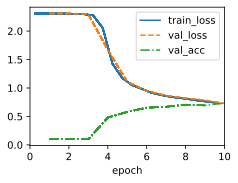

In [35]:
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
model = LeNet(lr=0.1)
model.apply_init([next(iter(data.get_dataloader(True)))[0]], init_cnn)
trainer.fit(model, data)

In [36]:
def evaluate_accuracy(model, data):
    model.eval()
    device = next(model.parameters()).device

    correct, total = 0, 0

    with torch.no_grad():
        for X, y in data.get_dataloader(train=False):
            X, y = X.to(device), y.to(device)
            y_hat = model(X)
            preds = y_hat.argmax(axis=1)

            correct += (preds == y).sum().item()
            total += y.numel()

    return correct / total

val_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Final validation accuracy: 73.40%


### 7.6.3 Summary

### 7.6.4 Exercises
1. Let's modernize LeNet. Implement and test the following changes:
    1. Replace average pooling with max-pooling.
    1. Replace the softmax layer with ReLU.
1. Try to change the size of the LeNet style network to improve its accuracy in addition to max-pooling and ReLU.
    1. Adjust the convolution window size.
    1. Adjust the number of output channels.
    1. Adjust the number of convolution layers.
    1. Adjust the number of fully connected layers.
    1. Adjust the learning rates and other training details (e.g., initialization and number of epochs).
1. Try out the improved network on the original MNIST dataset.
1. Display the activations of the first and second layer of LeNet for different inputs (e.g., sweaters and coats).
1. What happens to the activations when you feed significantly different images into the network (e.g., cats, cars, or even random noise)?


Exercise #1

In [ ]:
class ModernizedLeNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=6, kernel_size=5, padding=2), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(out_channels=16, kernel_size=5), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(out_features=120), nn.ReLU(),
            nn.LazyLinear(out_features=84), nn.ReLU(),
            nn.LazyLinear(out_features=num_classes)
        )

model = ModernizedLeNet()
model.layer_summary((1, 1, 28, 28))

Conv2d output shape:	 torch.Size([1, 6, 28, 28])
ReLU output shape:	 torch.Size([1, 6, 28, 28])
MaxPool2d output shape:	 torch.Size([1, 6, 14, 14])
Conv2d output shape:	 torch.Size([1, 16, 10, 10])
ReLU output shape:	 torch.Size([1, 16, 10, 10])
MaxPool2d output shape:	 torch.Size([1, 16, 5, 5])
Flatten output shape:	 torch.Size([1, 400])
Linear output shape:	 torch.Size([1, 120])
ReLU output shape:	 torch.Size([1, 120])
Linear output shape:	 torch.Size([1, 84])
ReLU output shape:	 torch.Size([1, 84])
Linear output shape:	 torch.Size([1, 10])


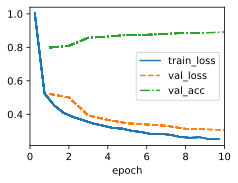

In [19]:
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
model = ModernizedLeNet(lr=0.1)
model.apply_init([next(iter(data.get_dataloader(True)))[0]], init_cnn)
trainer.fit(model, data)

Exercise #2 & #3

In [ ]:
# Accuracy of modernized LeNet
# Following code generated w/ GPT
def evaluate_accuracy(model, data):
    model.eval()
    device = next(model.parameters()).device

    correct, total = 0, 0

    with torch.no_grad():
        for X, y in data.get_dataloader(train=False):
            X, y = X.to(device), y.to(device)
            y_hat = model(X)
            preds = y_hat.argmax(axis=1)

            correct += (preds == y).sum().item()
            total += y.numel()

    return correct / total

val_acc = evaluate_accuracy(model, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Final validation accuracy: 89.20%


Final validation accuracy: 86.58%


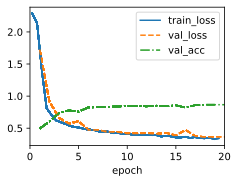

In [ ]:
# Try to beat ModernizedLeNet's 89.2% Validation Accuracy
# Can't. Tried a few configurations and below is best I can get with 86.58% validation accuracy
class OptimizedLeNet(d2l.Classifier):
    def __init__(self, lr=0.06, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=6, kernel_size=5, padding=2), nn.ReLU(),
            nn.LazyConv2d(out_channels=12, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.LazyConv2d(out_channels=16, kernel_size=5), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.LazyLinear(out_features=256), nn.ReLU(),
            nn.LazyLinear(out_features=256), nn.ReLU(),
            nn.LazyLinear(out_features=64), nn.ReLU(),
            nn.LazyLinear(out_features=num_classes)
        )

model_OptimLenet = OptimizedLeNet()
model_OptimLenet.layer_summary((1, 1, 28, 28))

trainer = d2l.Trainer(max_epochs=20, num_gpus=1)
data = d2l.FashionMNIST(batch_size=1024)
model_OptimLenet.apply_init([next(iter(data.get_dataloader(True)))[0]], init_cnn)
trainer.fit(model_OptimLenet, data)

val_acc = evaluate_accuracy(model_OptimLenet, data)
print(f"Final validation accuracy: {100 * val_acc:.2f}%")

Exercise #4 & 5

* Viewing activations of 1st and 2nd layers of LeNet for different inputs 
* I used GPT to handle viewing the layers

In [31]:
model_OptimLenet = OptimizedLeNet()
model_OptimLenet.layer_summary((1, 1, 28, 28))

Conv2d output shape:	 torch.Size([1, 6, 28, 28])
ReLU output shape:	 torch.Size([1, 6, 28, 28])
Conv2d output shape:	 torch.Size([1, 12, 28, 28])
ReLU output shape:	 torch.Size([1, 12, 28, 28])
MaxPool2d output shape:	 torch.Size([1, 12, 14, 14])
Conv2d output shape:	 torch.Size([1, 16, 10, 10])
ReLU output shape:	 torch.Size([1, 16, 10, 10])
MaxPool2d output shape:	 torch.Size([1, 16, 5, 5])
Flatten output shape:	 torch.Size([1, 400])
Linear output shape:	 torch.Size([1, 256])
ReLU output shape:	 torch.Size([1, 256])
Linear output shape:	 torch.Size([1, 256])
ReLU output shape:	 torch.Size([1, 256])
Linear output shape:	 torch.Size([1, 64])
ReLU output shape:	 torch.Size([1, 64])
Linear output shape:	 torch.Size([1, 10])


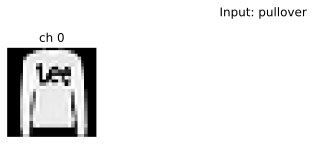

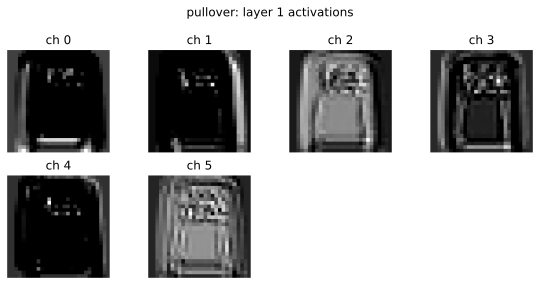

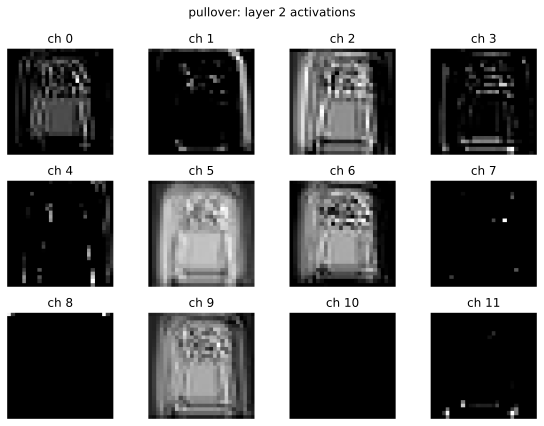

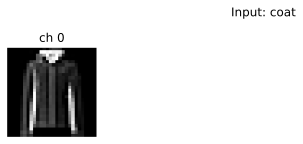

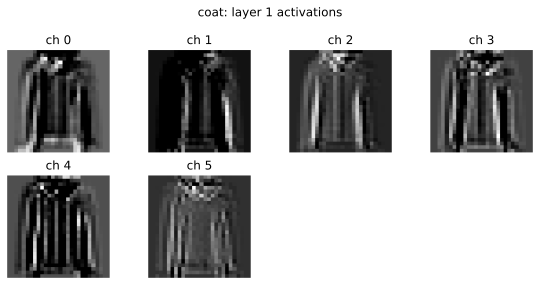

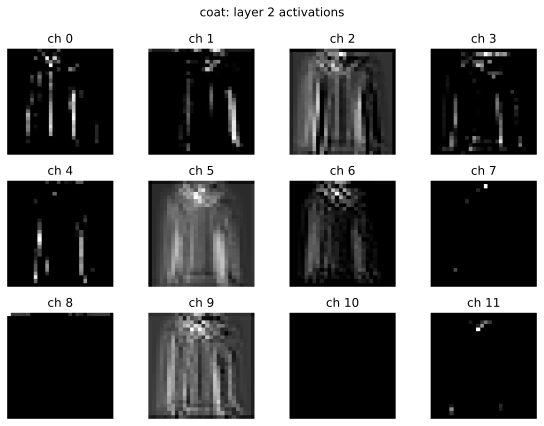

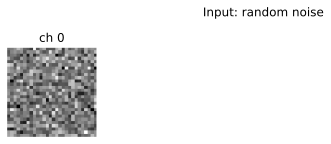

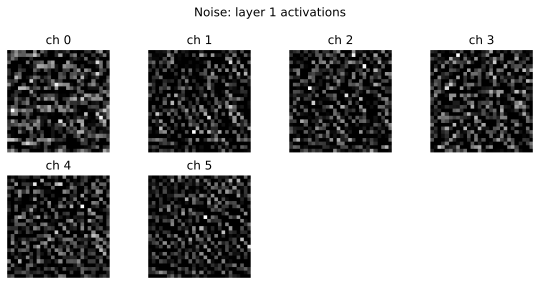

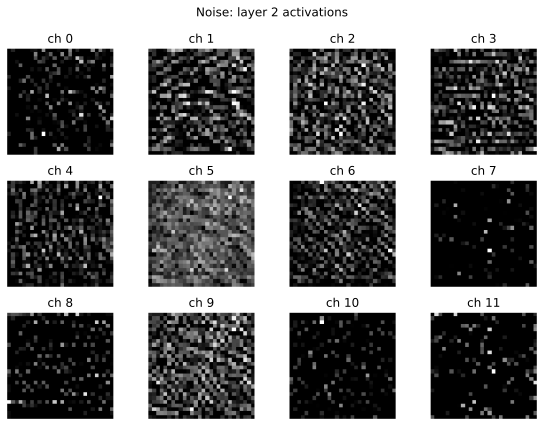

Prediction for random noise: trouser


In [ ]:
# Used GPT for this

import torch, math
import matplotlib.pyplot as plt

classes = ["t-shirt", "trouser", "pullover", "dress", "coat",
           "sandal", "shirt", "sneaker", "bag", "ankle boot"]

device = next(model_OptimLenet.parameters()).device

# Get one pullover and one coat from validation/test set
def get_imgs(data, wanted=(2, 4)):  # 2 = pullover, 4 = coat
    imgs = {}
    for X, y in data.get_dataloader(False):
        for i in range(len(y)):
            label = int(y[i])
            if label in wanted and label not in imgs:
                imgs[label] = X[i:i+1].to(device)
        if len(imgs) == len(wanted):
            break
    return imgs

# Get activations after selected layers
def get_acts(model, X, layers=(1, 3)):
    acts = {}
    model.eval()
    with torch.no_grad():
        for i, layer in enumerate(model.net):
            X = layer(X)
            if i in layers:
                acts[i] = X.cpu()
    return acts

# Plot input image or activation maps
def plot_maps(X, title, n=12):
    X = X.detach().cpu()
    # Remove batch dimension if present
    if X.ndim == 4:
        X = X[0]
    # If single image shape is H x W, add channel dimension
    if X.ndim == 2:
        X = X.unsqueeze(0)

    n = min(n, X.shape[0])
    cols = 4
    rows = math.ceil(n / cols)

    plt.figure(figsize=(2 * cols, 2 * rows))
    for i in range(n):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X[i], cmap="gray")
        plt.axis("off")
        plt.title(f"ch {i}")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Display activations for pullover and coat
imgs = get_imgs(data)

for label, X in imgs.items():
    acts = get_acts(model_OptimLenet, X)

    plot_maps(X, f"Input: {classes[label]}", n=1)
    plot_maps(acts[1], f"{classes[label]}: layer 1 activations", n=6)
    plot_maps(acts[3], f"{classes[label]}: layer 2 activations", n=12)

# Display activations for random noise
X_noise = torch.randn(1, 1, 28, 28).to(device)
acts_noise = get_acts(model_OptimLenet, X_noise)

plot_maps(X_noise, "Input: random noise", n=1)
plot_maps(acts_noise[1], "Noise: layer 1 activations", n=6)
plot_maps(acts_noise[3], "Noise: layer 2 activations", n=12)

# Prediction for random noise
with torch.no_grad():
    pred = model_OptimLenet(X_noise).argmax(1).item()

print("Prediction for random noise:", classes[pred])